**1-Mount  your Google Drive in Colab**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2- Access the folder containing your MobSF APK JSON analysis reports**

structure:

   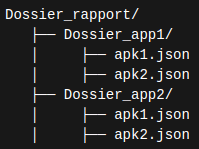

In [ ]:
import os

parent_dir = "/content/drive/MyDrive/Dossier_rapport/"#"/content/drive/MyDrive/UJKZ/These/My_works/tenYearMoBile/apk_reports/"# my example

total_subdirs = 0
total_apk = 0
one_apk_count = 0
multiple_apk_count = 0

for subdir in os.listdir(parent_dir):
    subdir_path = os.path.join(parent_dir, subdir)

    if os.path.isdir(subdir_path):
        total_subdirs += 1

        apk_files = [f for f in os.listdir(subdir_path) if f.lower().endswith(".json")]

        if len(apk_files) == 1:
            one_apk_count += 1
            #total_apk += 1
        elif len(apk_files) > 1:
            multiple_apk_count += 1
            total_apk += len(apk_files)

# Calcul du pourcentage
one_apk_percentage = (one_apk_count / total_subdirs * 100) if total_subdirs > 0 else 0
multiple_apk_percentage = (multiple_apk_count / total_subdirs * 100) if total_subdirs > 0 else 0

print("Nombre total de sous-dossiers :", total_subdirs)
print("Nombre total d\'APK splits:", total_apk)
print("Sous-dossiers avec un seul APK :", one_apk_count)
print(f"Pourcentage (1 APK) : {one_apk_percentage:.2f}%")

print("Sous-dossiers avec plusieurs APK :", multiple_apk_count)
print(f"Pourcentage (>1 APK) : {multiple_apk_percentage:.2f}%")

Nombre total de sous-dossiers : 49
Nombre total d'APK splits: 172
Sous-dossiers avec un seul APK : 11
Pourcentage (1 APK) : 22.45%
Sous-dossiers avec plusieurs APK : 38
Pourcentage (>1 APK) : 77.55%


In [ ]:
import os
import json

base_path = "/content/drive/MyDrive/Dossier_rapport/"#"/content/drive/MyDrive/UJKZ/These/My_works/tenYearMoBile/apk_reports/"# my example

reports = []

for root, dirs, files in os.walk(base_path):
    for file in files:
      if file.endswith(".json") and "_config" not in file and "_split" not in file and "_about" not in file: # We only keep the base files.
            file_path = os.path.join(root, file)

            try:
                with open(file_path, "r", encoding="utf-8") as f:
                    data = json.load(f)

                    # 🔥 Adding important metadata
                    data["file_name"] = file
                    data["folder_name"] = os.path.basename(root)
                    data["full_path"] = file_path

                    reports.append(data)

            except Exception as e:
                print(f"Erreur avec {file_path}: {e}")

print(f"✅ {len(reports)} fichiers JSON chargés")

✅ 49 fichiers JSON chargés


In [ ]:
print(type(reports))

<class 'list'>


**Verification**

In [ ]:
reports[0].keys()

dict_keys(['title', 'version', 'file_name', 'app_name', 'app_type', 'size', 'md5', 'sha1', 'sha256', 'package_name', 'main_activity', 'exported_activities', 'browsable_activities', 'activities', 'receivers', 'providers', 'services', 'libraries', 'target_sdk', 'max_sdk', 'min_sdk', 'version_name', 'version_code', 'icon_path', 'certificate_analysis', 'permissions', 'malware_permissions', 'manifest_analysis', 'network_security', 'binary_analysis', 'file_analysis', 'android_api', 'code_analysis', 'niap_analysis', 'permission_mapping', 'urls', 'domains', 'emails', 'strings', 'firebase_urls', 'files', 'exported_count', 'apkid', 'behaviour', 'trackers', 'playstore_details', 'secrets', 'logs', 'sbom', 'appsec', 'average_cvss', 'dynamic_analysis_done', 'virus_total', 'folder_name', 'full_path'])

In [ ]:
reports[0]["folder_name"], reports[0]["file_name"]

('com.mobiblanc.myonatel', 'com.mobiblanc.myonatel.apk.json')

**Mapping OWASP Mobile Top 10 (2023)**

👉 Based on your MobSF JSON (permissions, manifest, network, etc.)

In [ ]:
# Table CWE -> catégorie OWASP (pour les règles de "code_analysis")
CWE_OWASP = {
    "CWE-798": "M1_Improper_Credential_Usage",
    "CWE-89":  "M4_Input_Output",
    "CWE-79":  "M4_Input_Output",
    "CWE-749": "M4_Input_Output",
    "CWE-295": "M5_Insecure_Comm",
    "CWE-319": "M5_Insecure_Comm",
    "CWE-200": "M6_Privacy",
    "CWE-919": "M8_Misconfiguration",   # android_webview_debug
    "CWE-250": "M8_Misconfiguration",   # android_su_detect
    "CWE-276": "M9_Data_Storage",
    "CWE-312": "M9_Data_Storage",
    "CWE-532": "M9_Data_Storage",
    "CWE-327": "M10_Cryptography",
    "CWE-328": "M10_Cryptography",
    "CWE-329": "M10_Cryptography",
    "CWE-330": "M10_Cryptography",
    "CWE-649": "M10_Cryptography",
}

SEVERITES = ["high"]#, "warning"]   # même seuil pour toutes les sections


def map_owasp_2024(data):
    result = {
        "app": data.get("app_name"),
        "file_name": data.get("file_name"),
        "package_name": data.get("package_name"),
        "M1_Improper_Credential_Usage": 0,
        "M2_Supply_Chain": None,      # non évalué (et non 0)
        "M3_Insecure_Auth": None,     # non évalué (et non 0)
        "M4_Input_Output": 0,
        "M5_Insecure_Comm": 0,
        "M6_Privacy": 0,
        "M7_Binary_Protection": 0,
        "M8_Misconfiguration": 0,
        "M9_Data_Storage": 0,
        "M10_Cryptography": 0,
        "Non_classe": 0               # règles de code sans catégorie (à contrôler)
    }

    # M6 - Permissions dangereuses
    for p in (data.get("permissions") or {}).values():
        if p.get("status") == "dangerous":
            result["M6_Privacy"] += 1

    # M8 - Manifest (high + warning)
    # Les composants exportés sont comptés en M4 et le trafic en clair en M5 :
    # on les exclut ici pour ne pas les compter deux fois.
    manifest = data.get("manifest_analysis") or {}
    for f in manifest.get("manifest_findings", []):
        if f.get("severity") in SEVERITES:
            rule = (f.get("rule") or "").lower()
            if "exported" in rule:
                continue
            elif "clear_text" in rule or "cleartext" in rule:
                result["M5_Insecure_Comm"] += 1
            else:
                result["M8_Misconfiguration"] += 1

    # M4 - Composants exportés (activités, services, receivers, providers)
    exported = data.get("exported_count") or {}
    result["M4_Input_Output"] += sum(exported.values())

    # M5 - Network security (high + warning)
    for n in (data.get("network_security") or {}).get("network_findings", []):
        if n.get("severity") in SEVERITES:
            result["M5_Insecure_Comm"] += 1

    # M9 & M10 - Storage / Crypto (fichiers sensibles embarqués)
    for f in data.get("file_analysis") or []:
        finding = f.get("finding", "").lower()
        if "keystore" in finding:
            result["M10_Cryptography"] += 1
        else:
            result["M9_Data_Storage"] += 1

    # M7 - Certificat de signature
    cert = (data.get("certificate_analysis") or {}).get("certificate_summary", {})
    if cert.get("high", 0) > 0:
        result["M7_Binary_Protection"] += 1

    # M7 - Bibliothèques natives (.so) : contrôles de durcissement échoués
    for lib in data.get("binary_analysis") or []:
        for check in lib.values():
            if isinstance(check, dict) and check.get("severity") in SEVERITES:
                result["M7_Binary_Protection"] += 1

    # M1, M4, M5, M6, M9, M10 - Analyse du code (high + warning)
    code = (data.get("code_analysis") or {}).get("findings", {})
    for rule, f in code.items():
        meta = f.get("metadata", {})
        if meta.get("severity") not in SEVERITES:
            continue
        cwe = (meta.get("cwe") or "").split(":")[0].strip()   # ex. "CWE-327"
        if rule == "android_hardcoded":          # identifiants/clés codés en dur
            result["M1_Improper_Credential_Usage"] += 1
        elif cwe in CWE_OWASP:
            result[CWE_OWASP[cwe]] += 1
        else:
            result["Non_classe"] += 1

    return result




In [ ]:
def cwe_non_classees(reports):
    """Liste les règles de code (high/warning) dont la CWE n'est pas dans CWE_OWASP."""
    lignes = {}
    for data in reports:
        if isinstance(data, str):             # si l'élément est un chemin de fichier
            with open(data, encoding="utf-8") as fh:
                data = json.load(fh)
        code = (data.get("code_analysis") or {}).get("findings", {})
        for rule, f in code.items():
            meta = f.get("metadata", {})
            if meta.get("severity") not in SEVERITES:
                continue
            cwe = (meta.get("cwe") or "").split(":")[0].strip()
            #if rule == "android_hardcoded" or cwe in CWE_OWASP:
            #    continue                      # déjà classée par map_owasp_2024
            if rule not in lignes:
                lignes[rule] = {
                    "regle": rule,
                    "cwe": cwe or "(aucune)",
                    "cwe_libelle": meta.get("cwe", ""),
                    "masvs": meta.get("masvs", ""),
                    "severite": meta.get("severity"),
                    "description": meta.get("description", ""),
                    "nb_apps": 0,
                }
            lignes[rule]["nb_apps"] += 1
    colonnes = ["regle", "cwe", "cwe_libelle", "masvs", "severite", "description", "nb_apps"]
    df = pd.DataFrame(list(lignes.values()), columns=colonnes)
    return df.sort_values("nb_apps", ascending=False).reset_index(drop=True)

In [ ]:
df_manquantes = cwe_non_classees(reports)
df_manquantes

,regle,cwe,cwe_libelle,masvs,severite,description,nb_apps
0,android_read_write_external,CWE-276,CWE-276: Incorrect Default Permissions,MSTG-STORAGE-2,warning,App can read/write to External Storage. Any Ap...,48
1,android_temp_file,CWE-276,CWE-276: Incorrect Default Permissions,MSTG-STORAGE-2,warning,App creates temp file. Sensitive information s...,47
2,android_hardcoded,CWE-312,CWE-312: Cleartext Storage of Sensitive Inform...,MSTG-STORAGE-14,warning,Files may contain hardcoded sensitive informat...,45
3,android_sql_raw_query,CWE-89,CWE-89: Improper Neutralization of Special Ele...,,warning,App uses SQLite Database and execute raw SQL q...,45
4,android_insecure_random,CWE-330,CWE-330: Use of Insufficiently Random Values,MSTG-CRYPTO-6,warning,The App uses an insecure Random Number Generator.,44
5,android_sha1,CWE-327,CWE-327: Use of a Broken or Risky Cryptographi...,MSTG-CRYPTO-4,warning,SHA-1 is a weak hash known to have hash collis...,41
6,android_md5,CWE-327,CWE-327: Use of a Broken or Risky Cryptographi...,MSTG-CRYPTO-4,warning,MD5 is a weak hash known to have hash collisions.,34
7,android_ip_disclosure,CWE-200,CWE-200: Information Exposure,MSTG-CODE-2,warning,IP Address disclosure,31
8,android_webview,CWE-749,CWE-749: Exposed Dangerous Method or Function,MSTG-PLATFORM-7,warning,Insecure WebView Implementation. Execution of ...,30
9,cbc_padding_oracle,CWE-649,CWE-649: Reliance on Obfuscation or Encryption...,MSTG-CRYPTO-3,high,The App uses the encryption mode CBC with PKCS...,26



**Analysis of all apps**

In [ ]:
import pandas as pd
results = []

for data in reports:
    res = map_owasp_2024(data)
    results.append(res)

df = pd.DataFrame(results)

df

,app,file_name,package_name,M1_Improper_Credential_Usage,M2_Supply_Chain,M3_Insecure_Auth,M4_Input_Output,M5_Insecure_Comm,M6_Privacy,M7_Binary_Protection,M8_Misconfiguration,M9_Data_Storage,M10_Cryptography,Non_classe
0,MyMOOV,com.mobiblanc.myonatel.apk.json,com.mobiblanc.myonatel,0,None,None,3,3,2,0,1,0,0,0
1,Moov Money TD,td.moovmoney.mmpaysp.apk.json,td.moovmoney.mmpaysp,0,None,None,3,1,14,0,1,0,2,0
2,My Moov Mali,ml.moovmoney.mmpaysp.apk.json,ml.moovmoney.mmpaysp,0,None,None,4,1,13,0,1,0,2,0
3,QM Salone - Agent,com.qmoneysl.agents.apk.json,com.qmoneysl.agents,0,None,None,5,1,7,0,1,0,0,0
4,TNM Smart App,mw.co.tnm.topup.tnmsmartapp.apk.json,mw.co.tnm.topup.tnmsmartapp,0,None,None,5,2,9,0,1,0,1,0
5,My Moov Niger,www.mymoov.ne.apk.json,www.mymoov.ne,0,None,None,3,2,6,0,1,0,0,0
6,Moov Money Agent TD,td.moovmoney.mmpayorg.apk.json,td.moovmoney.mmpayorg,0,None,None,2,1,14,0,1,0,2,0
7,MOOV MONEY BURKINA FASO,bf.moovmoney.hwmm.apk.json,bf.moovmoney.hwmm,0,None,None,4,1,13,0,1,0,2,0
8,MTN MOMO PAY,com.skan.skanpaymtn.apk.json,com.skan.skanpaymtn,0,None,None,0,1,3,0,1,0,0,0
9,Orange Max it,com.orange.myorange.ocm.apk.json,com.orange.myorange.ocm,0,None,None,6,1,16,1,6,2,2,0


**Overall statistics**

In [ ]:
summary = df.drop(columns=["app","package_name","file_name"]).sum()#.sort_values(ascending=False)

print("=== Distribution OWASP Mobile Top 10 (2024) for base apk ===")
print(summary)

=== Distribution OWASP Mobile Top 10 (2024) for base apk ===
M1_Improper_Credential_Usage      0
M2_Supply_Chain                   0
M3_Insecure_Auth                  0
M4_Input_Output                 333
M5_Insecure_Comm                 61
M6_Privacy                      505
M7_Binary_Protection             35
M8_Misconfiguration              71
M9_Data_Storage                  20
M10_Cryptography                 44
Non_classe                        0
dtype: object


**Percentage of potentially vulnerable apps**

In [ ]:
percentage = (df.drop(columns=["app","package_name","file_name"]) > 0).sum() / len(df) * 100
#percentage = (df.drop(columns=["app"]) > 0).sum()

print("=== % Vulnerable apps (base APKs) by category ===")
print(percentage)

=== % Apps (base apk) vulnérables par catégorie ===
M1_Improper_Credential_Usage      0.000000
M2_Supply_Chain                   0.000000
M3_Insecure_Auth                  0.000000
M4_Input_Output                  97.959184
M5_Insecure_Comm                 71.428571
M6_Privacy                      100.000000
M7_Binary_Protection             14.285714
M8_Misconfiguration              91.836735
M9_Data_Storage                  26.530612
M10_Cryptography                 57.142857
Non_classe                        0.000000
dtype: float64


**Export CSV of base**

In [ ]:
import google.colab.files as gcs_files

df.to_csv("owasp_analysis_base.csv", index=False)

gcs_files.download("owasp_analysis_base.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Graphique**

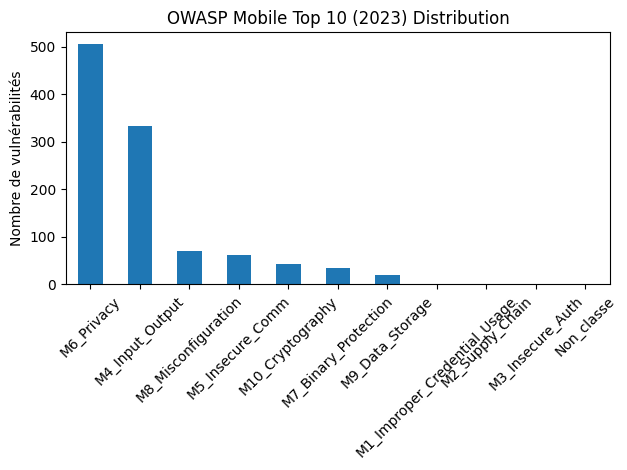

In [ ]:
import matplotlib.pyplot as plt

summary.plot(kind="bar")
plt.title("OWASP Mobile Top 10 (2024) Distribution")
plt.ylabel("Number of vulnerabilities")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**With only splits**

In [ ]:
reports_split = []

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.endswith(".json") and ("_config" in file or "_split" in file or "_about" in file):
            file_path = os.path.join(root, file)

            try:
                with open(file_path, "r", encoding="utf-8") as f:
                    data = json.load(f)

                    # 🔥Adding important metadata
                    data["file_name"] = file
                    data["folder_name"] = os.path.basename(root)
                    data["full_path"] = file_path

                    reports_split.append(data)

            except Exception as e:
                print(f"Erreur avec {file_path}: {e}")

print(f"✅ {len(reports_split)} fichiers JSON chargés")

✅ 134 fichiers JSON chargés


In [ ]:
import pandas as pd
results_split = []

for data in reports_split:
    res = map_owasp_2024(data)
    results_split.append(res)

df_split = pd.DataFrame(results_split)

df_split

,app,file_name,package_name,M1_Improper_Credential_Usage,M2_Supply_Chain,M3_Insecure_Auth,M4_Input_Output,M5_Insecure_Comm,M6_Privacy,M7_Binary_Protection,M8_Misconfiguration,M9_Data_Storage,M10_Cryptography,Non_classe
0,,td.moovmoney.mmpaysp_config.xhdpi.apk.json,td.moovmoney.mmpaysp,0,None,None,0,0,0,0,0,0,0,0
1,,td.moovmoney.mmpaysp_config.arm64_v8a.apk.json,td.moovmoney.mmpaysp,0,None,None,0,0,0,0,0,0,0,0
2,,ml.moovmoney.mmpaysp_config.xhdpi.apk.json,ml.moovmoney.mmpaysp,0,None,None,0,0,0,0,0,0,0,0
3,,ml.moovmoney.mmpaysp_config.arm64_v8a.apk.json,ml.moovmoney.mmpaysp,0,None,None,0,0,0,0,0,0,0,0
4,,com.qmoneysl.agents_config.arm64_v8a.apk.json,com.qmoneysl.agents,0,None,None,0,0,0,14,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129,,com.digitalpayment.benin.customer_config.arm64...,com.digitalpayment.benin.customer,0,None,None,0,0,0,0,0,0,0,0
130,,com.digitalpayment.benin.customer_config.xhdpi...,com.digitalpayment.benin.customer,0,None,None,0,0,0,0,0,0,0,0
131,,com.opareta.afrimoneyangola_config.arm64_v8a.a...,com.opareta.afrimoneyangola,0,None,None,0,0,0,0,0,0,0,0
132,,com.opareta.afrimoneyangola_config.xhdpi.apk.json,com.opareta.afrimoneyangola,0,None,None,0,0,0,0,0,0,0,0


In [ ]:
import google.colab.files as gcs_files

df_split.to_csv("owasp_analysis_split.csv", index=False)

gcs_files.download("owasp_analysis_split.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
summary_split = df_split.drop(columns=["app","package_name","file_name"]).sum().sort_values(ascending=False)

print("=== Distribution OWASP Mobile Top 10 (2024) splits ===")
print(summary_split)

=== Distribution OWASP Mobile Top 10 (2023) splits ===
M7_Binary_Protection            124
M1_Improper_Credential_Usage      0
M2_Supply_Chain                   0
M3_Insecure_Auth                  0
M4_Input_Output                   0
M5_Insecure_Comm                  0
M6_Privacy                        0
M8_Misconfiguration               0
M9_Data_Storage                   0
M10_Cryptography                  0
Non_classe                        0
dtype: object


In [ ]:
percentage_split = (df_split.drop(columns=["app","package_name","file_name"]) > 0).sum() / len(df_split) * 100
#percentage = (df.drop(columns=["app"]) > 0).sum()

print("=== % Vulnerable apps by category breakdown===")
print(percentage_split)

=== % Apps vulnérables par catégorie splits===
M1_Improper_Credential_Usage     0.000000
M2_Supply_Chain                  0.000000
M3_Insecure_Auth                 0.000000
M4_Input_Output                  0.000000
M5_Insecure_Comm                 0.000000
M6_Privacy                       0.000000
M7_Binary_Protection            19.402985
M8_Misconfiguration              0.000000
M9_Data_Storage                  0.000000
M10_Cryptography                 0.000000
Non_classe                       0.000000
dtype: float64


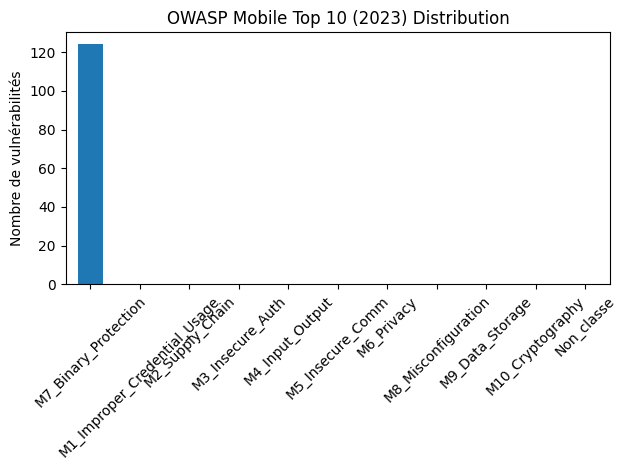

In [ ]:
import matplotlib.pyplot as plt

summary_split.plot(kind="bar")
plt.title("OWASP Mobile Top 10 (2024) Distribution")
plt.ylabel("Number of vulnerabilities")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()